# Explainable Bank Customer Churn Prediction and Retention Strategy

This notebook builds an academic bank customer churn prediction workflow using one local dataset:
`data/bank-churn-s4e1/train.csv`.

The workflow includes dynamic data inspection, exploratory data analysis, leakage-safe grouped validation,
feature engineering, model comparison, XGBoost tuning, out-of-fold threshold optimization, final holdout
evaluation, explainable AI, customer risk segmentation, banking retention strategy, and a dynamic conclusion.


## 1. Objective and Leakage Policy

`Exited` is the target variable: `1` means churn and `0` means retained.

The columns `id`, `CustomerId`, and `Exited` are never model features. `id` is a row identifier, `CustomerId`
is used only as the customer grouping key, and `Exited` is the target.

Because customers repeat, validation uses `StratifiedGroupKFold` grouped by `CustomerId`. The holdout set is
created once, has zero customer overlap with development data, and is used only after the model, parameters,
surname decision, and threshold are frozen.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import seaborn as sns
    SEABORN_AVAILABLE = True
except ImportError:
    sns = None
    SEABORN_AVAILABLE = False

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    import xgboost as xgb
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    xgb = None
    XGBClassifier = None
    XGBOOST_AVAILABLE = False

try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    shap = None
    SHAP_AVAILABLE = False

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
TARGET = "Exited"
DATA_PATH = Path(r"D:\FPT University\Coding\DSP\data\bank-churn-s4e1\train.csv")
IDENTIFIER_COLUMNS = ["id", "CustomerId"]
NON_FEATURE_COLUMNS = IDENTIFIER_COLUMNS + [TARGET]
FALSE_NEGATIVE_COST = 5
FALSE_POSITIVE_COST = 1

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

print("Configuration loaded.")
print(f"Data path: {DATA_PATH}")
print(f"XGBoost available: {XGBOOST_AVAILABLE}")
if XGBOOST_AVAILABLE:
    print("XGBoost version:", xgb.__version__)
    try:
        gpu_test_model = xgb.XGBClassifier(
            tree_method="hist",
            device="cuda",
            n_estimators=1,
        )
        print("XGBoost CUDA configuration enabled.")
    except Exception as e:
        print("CUDA configuration check failed:", e)
print(f"SHAP available: {SHAP_AVAILABLE}")


Configuration loaded.
Data path: D:\FPT University\Coding\DSP\data\bank-churn-s4e1\train.csv
XGBoost available: True
XGBoost version: 3.2.0
XGBoost CUDA configuration enabled.
SHAP available: True


c:\Users\admin\.conda\envs\dsp\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Dataset Loading and Dynamic Quality Check

This section loads the bank churn dataset and reports observed statistics dynamically. Dataset shape, columns,
data types, missing values, duplicate counts, and target distribution are not hard-coded.


In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset file was not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

expected_columns = [
    "id",
    "CustomerId",
    "Surname",
    "CreditScore",
    "Geography",
    "Gender",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited",
]

missing_expected_columns = [column for column in expected_columns if column not in df.columns]
unexpected_columns = [column for column in df.columns if column not in expected_columns]

if missing_expected_columns:
    raise KeyError(f"Missing expected columns: {missing_expected_columns}")

if TARGET not in df.columns:
    raise KeyError(f"Target column '{TARGET}' is missing.")

print("Dataset loaded successfully.")
print(f"Shape: {df.shape}")
print("Columns:")
print(df.columns.tolist())
print(f"Unexpected columns: {unexpected_columns if unexpected_columns else 'None'}")


Dataset loaded successfully.
Shape: (165034, 14)
Columns:
['id', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
Unexpected columns: None


In [3]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(4),
})

data_quality_summary = pd.DataFrame({
    "metric": [
        "rows",
        "columns",
        "exact_duplicate_rows",
        "unique_customers",
        "duplicated_customer_rows",
        "churn_rate_percent",
    ],
    "value": [
        len(df),
        df.shape[1],
        int(df.duplicated().sum()),
        int(df["CustomerId"].nunique()),
        int(df["CustomerId"].duplicated().sum()),
        round(float(df[TARGET].mean() * 100), 4),
    ],
})

target_counts = df[TARGET].value_counts().sort_index()
target_percentages = (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(4)

print("Data types:")
print(df.dtypes)
print("\nMissing values:")
print(missing_summary)
print("\nData quality summary:")
print(data_quality_summary)
print("\nTarget distribution counts:")
print(target_counts)
print("\nTarget distribution percentages:")
print(target_percentages)
print("\nFirst five rows:")
print(df.head())


Data types:
id                   int64
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                float64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard          float64
IsActiveMember     float64
EstimatedSalary    float64
Exited               int64
dtype: object

Missing values:
                 missing_count  missing_percentage
id                           0                 0.0
CustomerId                   0                 0.0
Surname                      0                 0.0
CreditScore                  0                 0.0
Geography                    0                 0.0
Gender                       0                 0.0
Age                          0                 0.0
Tenure                       0                 0.0
Balance                      0                 0.0
NumOfProducts                0                 0.0
HasCrCard         

## 3. Identifier and Surname Diagnostics

`id` and `CustomerId` are excluded from the feature matrix. `Surname` is not automatically discarded; it is
inspected and later tested through two development-only experiments.


In [4]:
identifier_diagnostics = []
for column in ["id", "CustomerId", "Surname"]:
    counts = df[column].value_counts(dropna=False)
    identifier_diagnostics.append({
        "column": column,
        "dtype": str(df[column].dtype),
        "unique_values": int(df[column].nunique(dropna=True)),
        "duplicate_rows": int(df[column].duplicated().sum()),
        "top_value": counts.index[0],
        "top_value_count": int(counts.iloc[0]),
    })

identifier_diagnostics_df = pd.DataFrame(identifier_diagnostics)
surname_frequency = df["Surname"].value_counts(dropna=False)

print(identifier_diagnostics_df)
print("\nTop 20 surnames:")
print(surname_frequency.head(20))
print("\nSurname frequency summary:")
print(surname_frequency.describe().to_frame("surname_frequency"))
print("\nSurname singleton count:")
print(int((surname_frequency == 1).sum()))


       column   dtype  unique_values  duplicate_rows top_value  top_value_count
0          id   int64         165034               0    165033                1
1  CustomerId   int64          23221          141813  15682355              121
2     Surname  object           2797          162237      Hsia             2456

Top 20 surnames:
Surname
Hsia                2456
T'ien               2282
Hs?                 1611
Maclean             1577
Kao                 1577
Ts'ui               1567
P'eng               1503
H?                  1420
Hsueh               1306
Shih                1251
Ch'ang              1229
Ch'iu               1199
Mazzanti            1192
Tuan                1164
Fanucci             1139
Onyemauchechukwu    1138
Tien                1132
Smith               1129
Nwankwo             1117
Manna               1024
Name: count, dtype: int64

Surname frequency summary:
       surname_frequency
count        2797.000000
mean           59.003933
std           167.357350


## 4. Group-Aware Development and Holdout Split

The internal holdout split uses grouped stratification. This gives approximately 80% development data and 20%
untouched holdout data, with no customer overlap.


In [5]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
groups_all = df["CustomerId"]
y_all = df[TARGET].astype(int)

development_index, holdout_index = next(splitter.split(df, y_all, groups=groups_all))
development_df = df.iloc[development_index].reset_index(drop=True)
holdout_df = df.iloc[holdout_index].reset_index(drop=True)

development_customers = set(development_df["CustomerId"].unique())
holdout_customers = set(holdout_df["CustomerId"].unique())
customer_overlap = development_customers.intersection(holdout_customers)

assert len(customer_overlap) == 0, "CustomerId leakage detected between development and holdout."

split_summary_df = pd.DataFrame({
    "split": ["development", "holdout"],
    "rows": [len(development_df), len(holdout_df)],
    "row_percentage": [len(development_df) / len(df) * 100, len(holdout_df) / len(df) * 100],
    "unique_customers": [development_df["CustomerId"].nunique(), holdout_df["CustomerId"].nunique()],
})

print("Grouped split completed.")
print(split_summary_df.round(4))
print(f"CustomerId overlap between development and holdout: {len(customer_overlap)}")


Grouped split completed.
         split    rows  row_percentage  unique_customers
0  development  132973         80.5731             18628
1      holdout   32061         19.4269              4593
CustomerId overlap between development and holdout: 0


## 5. Leakage-Safe Feature Engineering

Feature engineering is row-wise. It does not use target values, holdout labels, or full-dataset statistics.


In [6]:
def safe_divide(numerator, denominator):
    denominator = pd.Series(denominator).replace(0, np.nan)
    result = pd.Series(numerator) / denominator
    return result.replace([np.inf, -np.inf], np.nan).fillna(0.0)


def add_bank_features(frame):
    out = frame.copy()
    out["BalanceSalaryRatio"] = safe_divide(out["Balance"], out["EstimatedSalary"])
    out["BalancePerProduct"] = safe_divide(out["Balance"], out["NumOfProducts"])
    out["SalaryPerProduct"] = safe_divide(out["EstimatedSalary"], out["NumOfProducts"])
    out["CreditScoreAgeRatio"] = safe_divide(out["CreditScore"], out["Age"])
    out["TenureAgeRatio"] = safe_divide(out["Tenure"], out["Age"])
    out["InactiveWithBalance"] = ((out["IsActiveMember"].eq(0)) & (out["Balance"].gt(0))).astype(int)
    out["ActiveCardHolder"] = ((out["IsActiveMember"].eq(1)) & (out["HasCrCard"].eq(1))).astype(int)
    out["ProductActivityInteraction"] = out["NumOfProducts"] * out["IsActiveMember"]
    out["AgeProductInteraction"] = out["Age"] * out["NumOfProducts"]
    out["IsZeroBalance"] = out["Balance"].eq(0).astype(int)
    engineered_columns = [
        "BalanceSalaryRatio",
        "BalancePerProduct",
        "SalaryPerProduct",
        "CreditScoreAgeRatio",
        "TenureAgeRatio",
        "InactiveWithBalance",
        "ActiveCardHolder",
        "ProductActivityInteraction",
        "AgeProductInteraction",
        "IsZeroBalance",
    ]
    out[engineered_columns] = out[engineered_columns].replace([np.inf, -np.inf], np.nan).fillna(0.0)
    return out


development_fe = add_bank_features(development_df)
X_development = development_fe.drop(columns=NON_FEATURE_COLUMNS, errors="raise")
y_development = development_fe[TARGET].astype(int)
groups_development = development_fe["CustomerId"]

for forbidden_column in NON_FEATURE_COLUMNS:
    assert forbidden_column not in X_development.columns, f"{forbidden_column} leaked into model features."

print("Development feature matrix created.")
print(f"X_development shape: {X_development.shape}")
print(f"y_development shape: {y_development.shape}")
print("Engineered feature columns:")
print([column for column in development_fe.columns if column not in df.columns])
print("Forbidden model columns present:")
print([column for column in NON_FEATURE_COLUMNS if column in X_development.columns])


Development feature matrix created.
X_development shape: (132973, 21)
y_development shape: (132973,)
Engineered feature columns:
['BalanceSalaryRatio', 'BalancePerProduct', 'SalaryPerProduct', 'CreditScoreAgeRatio', 'TenureAgeRatio', 'InactiveWithBalance', 'ActiveCardHolder', 'ProductActivityInteraction', 'AgeProductInteraction', 'IsZeroBalance']
Forbidden model columns present:
[]


## 6. Exploratory Data Analysis on Development Data

EDA is performed on development data so holdout remains reserved for final evaluation.


In [7]:
eda_df = development_fe.copy()
eda_summary_df = pd.DataFrame({
    "metric": ["samples", "raw_features_excluding_target", "development_churn_percent"],
    "value": [len(eda_df), df.shape[1] - 1, round(float(eda_df[TARGET].mean() * 100), 4)],
})
print(eda_summary_df)


                          metric        value
0                        samples  132973.0000
1  raw_features_excluding_target      13.0000
2      development_churn_percent      21.2148


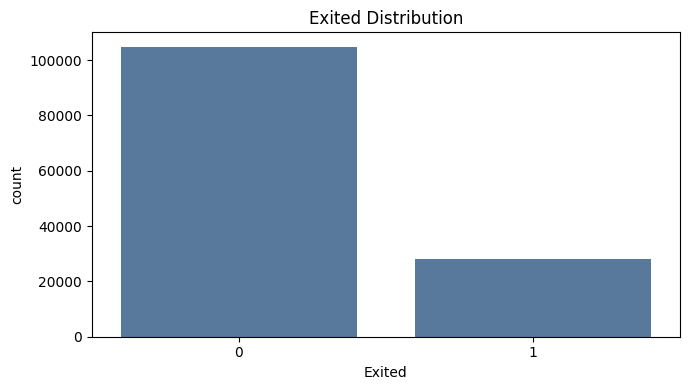

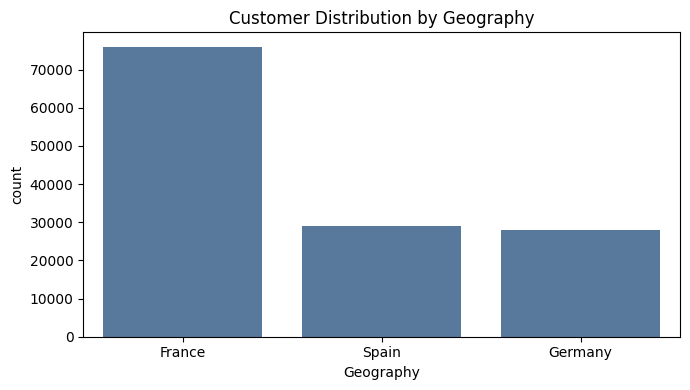

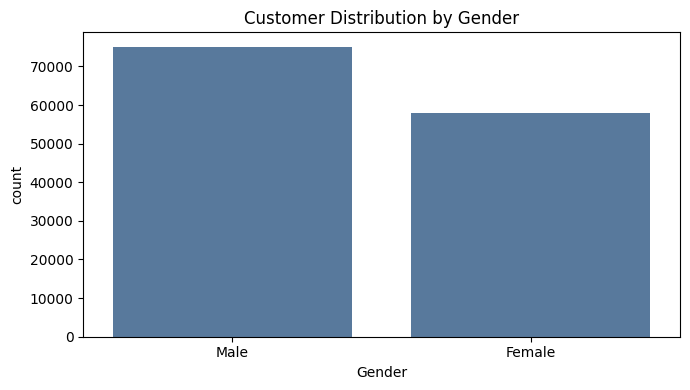

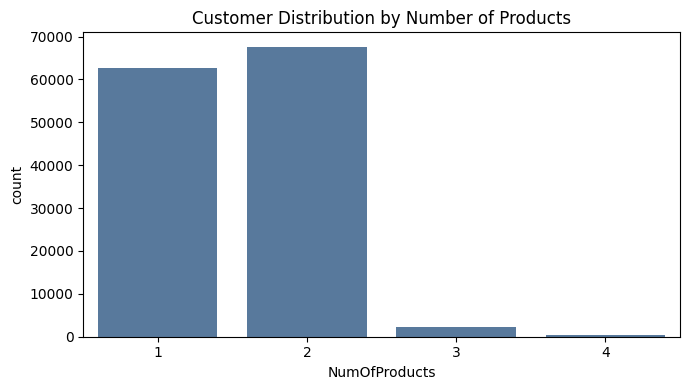

   Exited   count
0       0  104763
1       1   28210


In [8]:
def plot_count(column, title, rotation=0):
    counts = eda_df[column].value_counts(dropna=False).reset_index()
    counts.columns = [column, "count"]
    plt.figure(figsize=(7, 4))
    if SEABORN_AVAILABLE:
        sns.barplot(data=counts, x=column, y="count", color="#4C78A8")
    else:
        plt.bar(counts[column].astype(str), counts["count"], color="#4C78A8")
    plt.title(title)
    plt.xticks(rotation=rotation)
    plt.tight_layout()
    plt.show()
    return counts

exited_distribution = plot_count(TARGET, "Exited Distribution")
geography_distribution = plot_count("Geography", "Customer Distribution by Geography")
gender_distribution = plot_count("Gender", "Customer Distribution by Gender")
product_distribution = plot_count("NumOfProducts", "Customer Distribution by Number of Products")

print(exited_distribution)


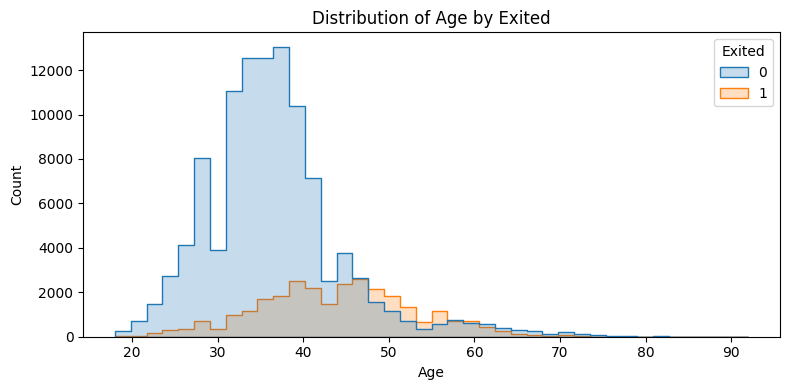

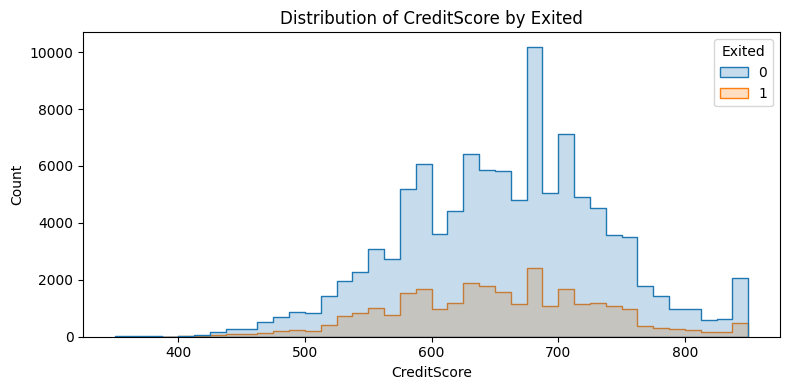

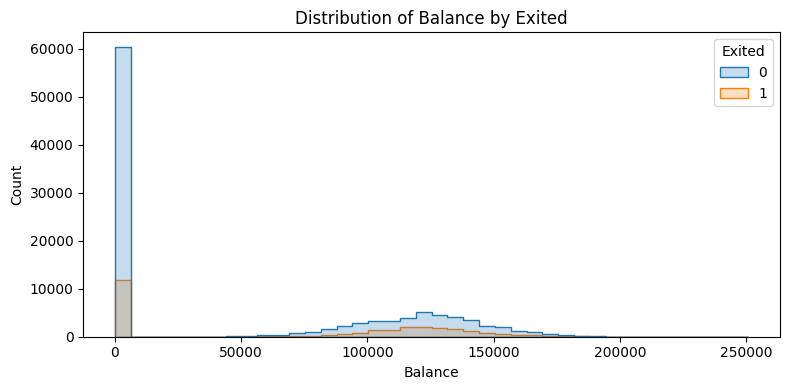

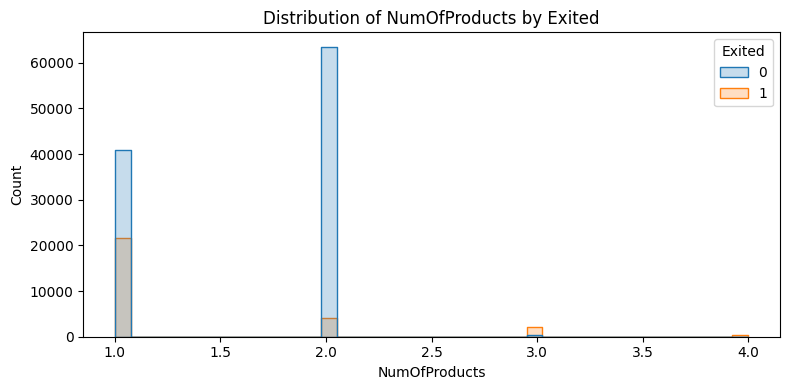

In [9]:
def plot_numeric_distribution(column, title, bins=40):
    plt.figure(figsize=(8, 4))
    if SEABORN_AVAILABLE:
        sns.histplot(data=eda_df, x=column, hue=TARGET, bins=bins, kde=False, element="step")
    else:
        for target_value in sorted(eda_df[TARGET].unique()):
            plt.hist(eda_df.loc[eda_df[TARGET].eq(target_value), column], bins=bins, alpha=0.5, label=f"Exited={target_value}")
        plt.legend()
    plt.title(title)
    plt.tight_layout()
    plt.show()

for numeric_column in ["Age", "CreditScore", "Balance", "NumOfProducts"]:
    plot_numeric_distribution(numeric_column, f"Distribution of {numeric_column} by Exited")


In [10]:
def churn_summary_by(column):
    summary = (
        eda_df.groupby(column, dropna=False, observed=False)[TARGET]
        .agg(customer_count="size", churn_count="sum", churn_rate="mean")
        .reset_index()
    )
    summary["churn_rate_percent"] = (summary["churn_rate"] * 100).round(4)
    return summary.sort_values("churn_rate", ascending=False)

eda_df["AgeGroup"] = pd.cut(
    eda_df["Age"],
    bins=[0, 30, 40, 50, 60, np.inf],
    labels=["18-30", "31-40", "41-50", "51-60", "60+"],
    include_lowest=True,
)
eda_df["CreditScoreBand"] = pd.cut(
    eda_df["CreditScore"],
    bins=[0, 579, 669, 739, 799, np.inf],
    labels=["Poor", "Fair", "Good", "Very Good", "Excellent"],
    include_lowest=True,
)
eda_df["BalanceCategory"] = pd.cut(
    eda_df["Balance"],
    bins=[-0.01, 0, 50000, 100000, 150000, np.inf],
    labels=["Zero", "Low", "Medium", "High", "Very High"],
    include_lowest=True,
)

churn_tables = {
    "Geography": churn_summary_by("Geography"),
    "Gender": churn_summary_by("Gender"),
    "AgeGroup": churn_summary_by("AgeGroup"),
    "CreditScoreBand": churn_summary_by("CreditScoreBand"),
    "NumOfProducts": churn_summary_by("NumOfProducts"),
    "IsActiveMember": churn_summary_by("IsActiveMember"),
    "BalanceCategory": churn_summary_by("BalanceCategory"),
}

for table_name, table in churn_tables.items():
    print(f"\nChurn by {table_name}:")
    print(table)



Churn by Geography:
  Geography  customer_count  churn_count  churn_rate  churn_rate_percent
1   Germany           27946        10622    0.380090             38.0090
2     Spain           29057         4988    0.171663             17.1663
0    France           75970        12600    0.165855             16.5855

Churn by Gender:
   Gender  customer_count  churn_count  churn_rate  churn_rate_percent
0  Female           57909        16233    0.280319             28.0319
1    Male           75064        11977    0.159557             15.9557

Churn by AgeGroup:
  AgeGroup  customer_count  churn_count  churn_rate  churn_rate_percent
3    51-60            9022         5478    0.607182             60.7182
2    41-50           29858        11643    0.389946             38.9946
4      60+            3237         1019    0.314798             31.4798
1    31-40           67773         8177    0.120653             12.0653
0    18-30           23083         1893    0.082008              8.2008

Chu

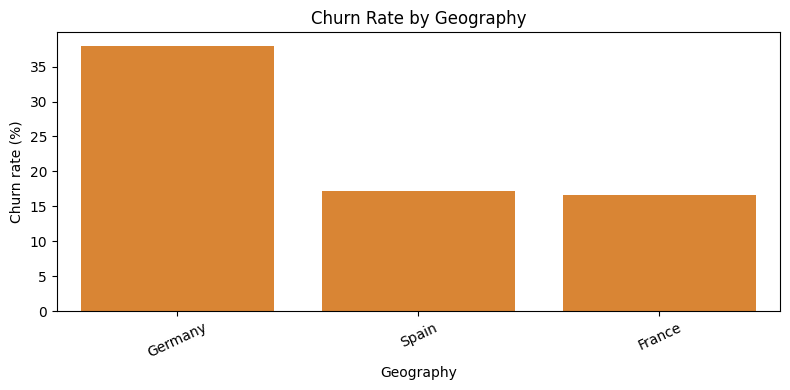

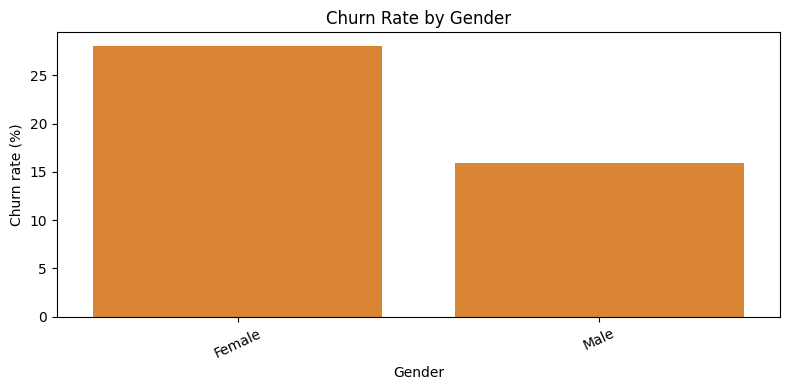

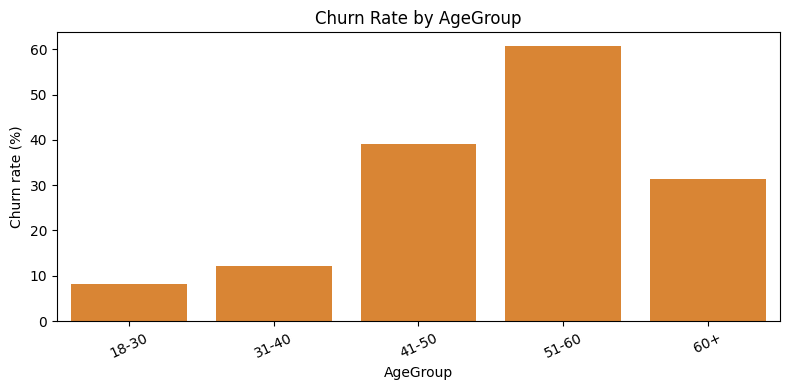

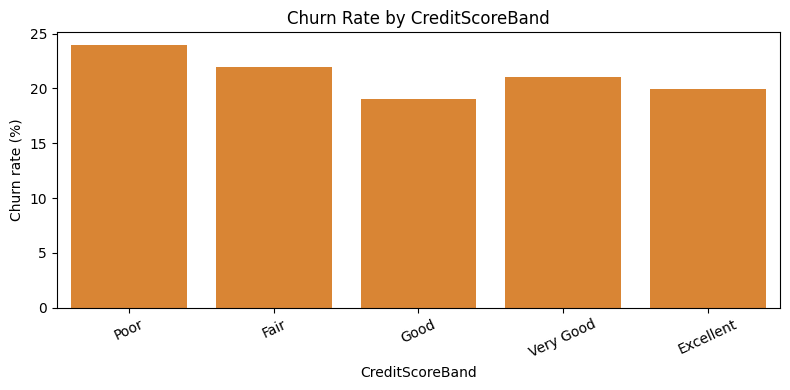

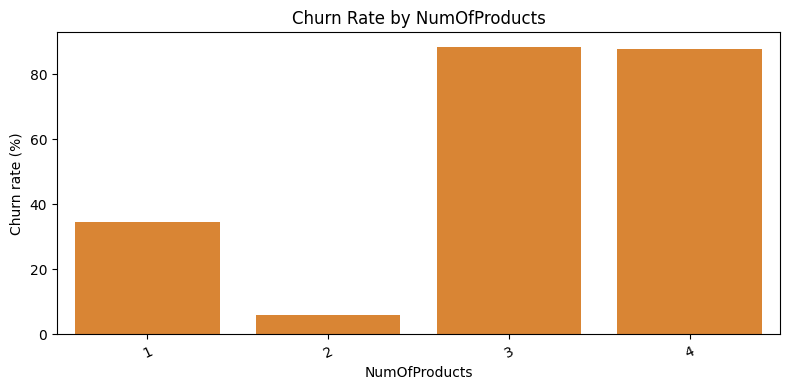

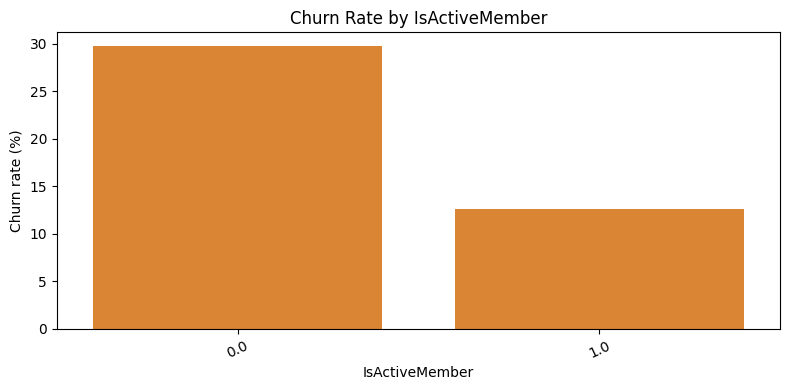

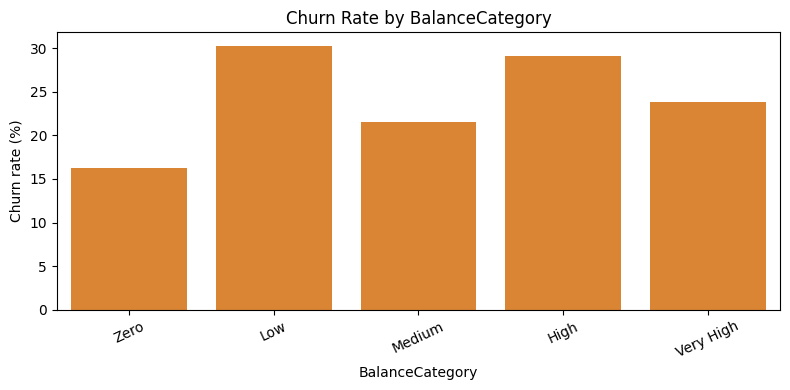

In [11]:
def plot_churn_rate(summary_df, category_column, title, rotation=25):
    plot_df = summary_df.copy()
    plt.figure(figsize=(8, 4))
    if SEABORN_AVAILABLE:
        sns.barplot(data=plot_df, x=category_column, y="churn_rate_percent", color="#F58518")
    else:
        plt.bar(plot_df[category_column].astype(str), plot_df["churn_rate_percent"], color="#F58518")
    plt.title(title)
    plt.ylabel("Churn rate (%)")
    plt.xticks(rotation=rotation)
    plt.tight_layout()
    plt.show()

for category_name, table in churn_tables.items():
    plot_churn_rate(table, category_name, f"Churn Rate by {category_name}")


## 7. Preprocessing and Model Pipeline Factory

Preprocessing is inside sklearn pipelines. Numeric imputation, scaling, categorical imputation, and one-hot
encoding are learned inside each development fold.


In [12]:
BASE_CATEGORICAL_FEATURES = [
    "Geography",
    "Gender",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "InactiveWithBalance",
    "ActiveCardHolder",
    "IsZeroBalance",
]

modeling_feature_columns = X_development.columns.tolist()


def make_preprocessor(include_surname=False):
    categorical_features = [column for column in BASE_CATEGORICAL_FEATURES if column in modeling_feature_columns]
    if include_surname and "Surname" in modeling_feature_columns:
        categorical_features = categorical_features + ["Surname"]

    excluded_columns = set()
    if not include_surname:
        excluded_columns.add("Surname")

    numeric_features = [
        column for column in modeling_feature_columns
        if column not in categorical_features and column not in excluded_columns
    ]

    forbidden_in_preprocessor = set(NON_FEATURE_COLUMNS).intersection(categorical_features + numeric_features)
    assert not forbidden_in_preprocessor, f"Forbidden columns in preprocessor: {forbidden_in_preprocessor}"

    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)),
    ])

    return ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features),
        ],
        remainder="drop",
    )


negative_count = int((y_development == 0).sum())
positive_count = int((y_development == 1).sum())
scale_pos_weight = negative_count / positive_count if positive_count else 1.0


def build_model_pipeline(model_key, include_surname=False, xgb_params=None):
    preprocessor = make_preprocessor(include_surname=include_surname)
    if model_key == "logistic_regression":
        classifier = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
    elif model_key == "extra_trees":
        classifier = ExtraTreesClassifier(n_estimators=400, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
    elif model_key == "xgboost":
        if not XGBOOST_AVAILABLE:
            raise ImportError("XGBoost is not available in this environment.")
        base_params = {
            "objective": "binary:logistic",
            "eval_metric": "logloss",
            "tree_method": "hist",
            "device": "cuda",
            "random_state": RANDOM_STATE,
            "n_jobs": -1,
            "scale_pos_weight": scale_pos_weight,
        }
        if xgb_params:
            base_params.update(xgb_params)
        classifier = XGBClassifier(**base_params)
    else:
        raise ValueError(f"Unknown model key: {model_key}")

    return Pipeline(steps=[("preprocessor", preprocessor), ("classifier", classifier)])


logistic_pipeline_template = build_model_pipeline("logistic_regression", include_surname=False)
extra_trees_pipeline_template = build_model_pipeline("extra_trees", include_surname=False)
xgboost_pipeline_template = build_model_pipeline("xgboost", include_surname=False) if XGBOOST_AVAILABLE else None

print("Pipeline templates initialized without fitting.")
print(f"Scale_pos_weight for development data: {scale_pos_weight:.4f}")
print(f"id in modeling features: {'id' in modeling_feature_columns}")
print(f"CustomerId in modeling features: {'CustomerId' in modeling_feature_columns}")


Pipeline templates initialized without fitting.
Scale_pos_weight for development data: 3.7137
id in modeling features: False
CustomerId in modeling features: False


## 8. Surname Experiment on Development Cross-Validation

Experiment A drops `Surname`. Experiment B keeps `Surname` with
`OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)`. The better approach is selected from
development grouped cross-validation only. If the improvement is insignificant, the notebook prefers dropping
`Surname`.


In [13]:
SURNAME_EXPERIMENT_CV_SPLITS = 3
SURNAME_MIN_ROC_AUC_GAIN = 0.002
surname_cv = StratifiedGroupKFold(n_splits=SURNAME_EXPERIMENT_CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

surname_experiment_models = {
    "Experiment A - Drop Surname": build_model_pipeline("logistic_regression", include_surname=False),
    "Experiment B - Keep Surname": build_model_pipeline("logistic_regression", include_surname=True),
}

surname_experiment_rows = []
for experiment_name, experiment_model in surname_experiment_models.items():
    cv_scores = cross_validate(
        experiment_model,
        X_development,
        y_development,
        groups=groups_development,
        cv=surname_cv,
        scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
        n_jobs=-1,
        return_train_score=False,
    )
    surname_experiment_rows.append({
        "Experiment": experiment_name,
        "Mean ROC-AUC": float(np.mean(cv_scores["test_roc_auc"])),
        "Std ROC-AUC": float(np.std(cv_scores["test_roc_auc"], ddof=1)),
        "Mean PR-AUC": float(np.mean(cv_scores["test_pr_auc"])),
    })

surname_experiment_df = pd.DataFrame(surname_experiment_rows).sort_values("Mean ROC-AUC", ascending=False)
surname_auc_drop = float(surname_experiment_df.loc[surname_experiment_df["Experiment"].eq("Experiment A - Drop Surname"), "Mean ROC-AUC"].iloc[0])
surname_auc_keep = float(surname_experiment_df.loc[surname_experiment_df["Experiment"].eq("Experiment B - Keep Surname"), "Mean ROC-AUC"].iloc[0])
surname_auc_gain = surname_auc_keep - surname_auc_drop
USE_SURNAME = bool(surname_auc_gain >= SURNAME_MIN_ROC_AUC_GAIN)

print(surname_experiment_df)
print(f"ROC-AUC gain from keeping Surname: {surname_auc_gain:.6f}")
print(f"Surname selected for downstream models: {USE_SURNAME}")


                    Experiment  Mean ROC-AUC  Std ROC-AUC  Mean PR-AUC
1  Experiment B - Keep Surname      0.879770     0.002622     0.695919
0  Experiment A - Drop Surname      0.876616     0.002987     0.693418
ROC-AUC gain from keeping Surname: 0.003154
Surname selected for downstream models: True


## 9. Development Cross-Validated Model Comparison

The model set is Logistic Regression, Extra Trees, and XGBoost. All estimates use grouped cross-validation on
development data.


In [14]:
MODEL_CV_SPLITS = 5
development_cv = StratifiedGroupKFold(n_splits=MODEL_CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}


def extract_positive_class_probabilities(raw_predictions):
    prediction_array = np.asarray(raw_predictions)
    if prediction_array.ndim != 2 or prediction_array.shape[1] < 2:
        raise ValueError("predict_proba did not return a positive-class probability column.")
    return prediction_array[:, 1]


def evaluate_model_with_group_cv(model_name, model, cv):
    cv_result = cross_validate(
        model,
        X_development,
        y_development,
        groups=groups_development,
        cv=cv,
        scoring=cv_scoring,
        n_jobs=-1,
        return_train_score=True,
    )
    raw_oof_probabilities = cross_val_predict(
        model,
        X_development,
        y_development,
        groups=groups_development,
        cv=cv,
        method="predict_proba",
        n_jobs=-1,
    )
    oof_probabilities = extract_positive_class_probabilities(raw_oof_probabilities)
    oof_predictions_at_half = (oof_probabilities >= 0.5).astype(int)
    row = {
        "Model": model_name,
        "CV ROC-AUC Mean": float(np.mean(cv_result["test_roc_auc"])),
        "CV ROC-AUC Std": float(np.std(cv_result["test_roc_auc"], ddof=1)),
        "CV PR-AUC Mean": float(np.mean(cv_result["test_pr_auc"])),
        "CV PR-AUC Std": float(np.std(cv_result["test_pr_auc"], ddof=1)),
        "CV Precision Mean": float(np.mean(cv_result["test_precision"])),
        "CV Recall Mean": float(np.mean(cv_result["test_recall"])),
        "CV F1-score Mean": float(np.mean(cv_result["test_f1"])),
        "OOF ROC-AUC": float(roc_auc_score(y_development, oof_probabilities)),
        "OOF PR-AUC": float(average_precision_score(y_development, oof_probabilities)),
        "OOF Precision at 0.5": float(precision_score(y_development, oof_predictions_at_half, zero_division=0)),
        "OOF Recall at 0.5": float(recall_score(y_development, oof_predictions_at_half, zero_division=0)),
        "OOF F1-score at 0.5": float(f1_score(y_development, oof_predictions_at_half, zero_division=0)),
        "Train ROC-AUC Mean": float(np.mean(cv_result["train_roc_auc"])),
        "ROC-AUC Overfit Gap": float(np.mean(cv_result["train_roc_auc"]) - np.mean(cv_result["test_roc_auc"])),
    }
    return row, oof_probabilities


model_objects = {
    "Logistic Regression": build_model_pipeline("logistic_regression", include_surname=USE_SURNAME),
    "Extra Trees": build_model_pipeline("extra_trees", include_surname=USE_SURNAME),
}
if XGBOOST_AVAILABLE:
    model_objects["XGBoost Baseline"] = build_model_pipeline("xgboost", include_surname=USE_SURNAME)

model_cv_rows = []
model_oof_probabilities = {}
for model_name, model in model_objects.items():
    row, oof_probabilities = evaluate_model_with_group_cv(model_name, model, development_cv)
    model_cv_rows.append(row)
    model_oof_probabilities[model_name] = oof_probabilities

model_cv_results_df = pd.DataFrame(model_cv_rows).sort_values("CV ROC-AUC Mean", ascending=False).reset_index(drop=True)
print(model_cv_results_df)


                 Model  CV ROC-AUC Mean  CV ROC-AUC Std  CV PR-AUC Mean  CV PR-AUC Std  CV Precision Mean  CV Recall Mean  \
0     XGBoost Baseline         0.890530        0.003395        0.732830       0.008747           0.549302        0.787538   
1  Logistic Regression         0.880059        0.002937        0.696390       0.008787           0.514688        0.803640   
2          Extra Trees         0.877373        0.002669        0.707571       0.007354           0.715174        0.561240   

   CV F1-score Mean  OOF ROC-AUC  OOF PR-AUC  OOF Precision at 0.5  OOF Recall at 0.5  OOF F1-score at 0.5  Train ROC-AUC Mean  \
0          0.647169     0.890530    0.732707              0.549295           0.787629             0.647218            0.915982   
1          0.627468     0.880059    0.696347              0.514664           0.803687             0.627494            0.886455   
2          0.628870     0.877377    0.707558              0.713894           0.563524             0.629859   

## 10. XGBoost Hyperparameter Tuning

`QUICK_TUNING_MODE=True` uses `RandomizedSearchCV` with three-fold grouped validation and 20 iterations. The
primary selection metric is ROC-AUC.


In [15]:
QUICK_TUNING_MODE = True
N_ITER_SEARCH = 20 if QUICK_TUNING_MODE else 30
XGB_TUNING_CV_SPLITS = 3
xgb_tuned_search = None
xgb_tuned_best_model = None

if XGBOOST_AVAILABLE:
    xgb_tuning_cv = StratifiedGroupKFold(n_splits=XGB_TUNING_CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    xgb_tuning_pipeline = build_model_pipeline("xgboost", include_surname=USE_SURNAME)
    xgb_param_distributions = {
        "classifier__n_estimators": [300, 500, 700, 900, 1200],
        "classifier__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.08, 0.10],
        "classifier__max_depth": [2, 3, 4, 5, 6],
        "classifier__min_child_weight": [1, 2, 3, 5, 8, 10],
        "classifier__gamma": [0, 0.01, 0.05, 0.10, 0.20, 0.50],
        "classifier__subsample": [0.65, 0.75, 0.85, 0.95, 1.00],
        "classifier__colsample_bytree": [0.60, 0.70, 0.80, 0.90, 1.00],
        "classifier__reg_alpha": [0, 0.001, 0.01, 0.10, 0.50, 1.00, 5.00],
        "classifier__reg_lambda": [0.10, 0.50, 1.00, 2.00, 5.00, 10.00, 20.00],
        "classifier__scale_pos_weight": sorted(set([1.0, 2.0, 3.0, 4.0, 5.0, round(scale_pos_weight, 4)])),
    }
    xgb_tuned_search = RandomizedSearchCV(
        estimator=xgb_tuning_pipeline,
        param_distributions=xgb_param_distributions,
        n_iter=N_ITER_SEARCH,
        scoring=cv_scoring,
        refit="roc_auc",
        cv=xgb_tuning_cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
        return_train_score=True,
    )
    xgb_tuned_search.fit(X_development, y_development, groups=groups_development)
    xgb_tuned_best_model = xgb_tuned_search.best_estimator_
    model_objects["XGBoost Tuned"] = xgb_tuned_best_model
    tuned_row, tuned_oof_probabilities = evaluate_model_with_group_cv("XGBoost Tuned", xgb_tuned_best_model, development_cv)
    model_oof_probabilities["XGBoost Tuned"] = tuned_oof_probabilities
    model_cv_results_df = pd.concat([model_cv_results_df, pd.DataFrame([tuned_row])], ignore_index=True)
    model_cv_results_df = model_cv_results_df.sort_values("CV ROC-AUC Mean", ascending=False).reset_index(drop=True)
    print(f"QUICK_TUNING_MODE: {QUICK_TUNING_MODE}")
    print(f"RandomizedSearchCV iterations: {N_ITER_SEARCH}")
    print(f"Tuning CV splits: {XGB_TUNING_CV_SPLITS}")
    print("Best parameters:")
    print(xgb_tuned_search.best_params_)
    print("Best tuning ROC-AUC:")
    print(round(float(xgb_tuned_search.best_score_), 6))
else:
    print("XGBoost is unavailable, so tuning is skipped.")

print(model_cv_results_df)


Fitting 3 folds for each of 20 candidates, totalling 60 fits
QUICK_TUNING_MODE: True
RandomizedSearchCV iterations: 20
Tuning CV splits: 3
Best parameters:
{'classifier__subsample': 0.95, 'classifier__scale_pos_weight': 1.0, 'classifier__reg_lambda': 20.0, 'classifier__reg_alpha': 0.5, 'classifier__n_estimators': 900, 'classifier__min_child_weight': 2, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.1, 'classifier__gamma': 0.5, 'classifier__colsample_bytree': 0.9}
Best tuning ROC-AUC:
0.893367
                 Model  CV ROC-AUC Mean  CV ROC-AUC Std  CV PR-AUC Mean  CV PR-AUC Std  CV Precision Mean  CV Recall Mean  \
0        XGBoost Tuned         0.893232        0.002849        0.739271       0.008404           0.747894        0.563647   
1     XGBoost Baseline         0.890530        0.003395        0.732830       0.008747           0.549302        0.787538   
2  Logistic Regression         0.880059        0.002937        0.696390       0.008787           0.514688        0.

## 11. Model Selection from Development Data

The selected model is chosen by development ROC-AUC only. Holdout results are not used for model selection.


In [16]:
if model_cv_results_df.empty:
    raise ValueError("No model comparison results are available.")

model_selection_df = model_cv_results_df.sort_values(
    by=["CV ROC-AUC Mean", "CV PR-AUC Mean", "CV F1-score Mean"],
    ascending=False,
).reset_index(drop=True)

selected_model_name = model_selection_df.loc[0, "Model"]
selected_model_template = model_objects[selected_model_name]
selected_model_oof_probabilities = model_oof_probabilities[selected_model_name]

print(model_selection_df)
print("\nSelected model from development CV:")
print(selected_model_name)


                 Model  CV ROC-AUC Mean  CV ROC-AUC Std  CV PR-AUC Mean  CV PR-AUC Std  CV Precision Mean  CV Recall Mean  \
0        XGBoost Tuned         0.893232        0.002849        0.739271       0.008404           0.747894        0.563647   
1     XGBoost Baseline         0.890530        0.003395        0.732830       0.008747           0.549302        0.787538   
2  Logistic Regression         0.880059        0.002937        0.696390       0.008787           0.514688        0.803640   
3          Extra Trees         0.877373        0.002669        0.707571       0.007354           0.715174        0.561240   

   CV F1-score Mean  OOF ROC-AUC  OOF PR-AUC  OOF Precision at 0.5  OOF Recall at 0.5  OOF F1-score at 0.5  Train ROC-AUC Mean  \
0          0.642758     0.893237    0.739292              0.747872           0.563807             0.642925            0.905092   
1          0.647169     0.890530    0.732707              0.549295           0.787629             0.647218        

## 12. Out-of-Fold Threshold Optimization

The decision threshold is selected from development out-of-fold probabilities only. The search range is 0.05 to
0.95 with a 0.01 step. Business cost assumes false negatives cost 5 and false positives cost 1.


In [17]:
def calculate_binary_metrics(y_true, probabilities, threshold):
    y_pred = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    business_cost = fn * FALSE_NEGATIVE_COST + fp * FALSE_POSITIVE_COST
    return {
        "Threshold": float(threshold),
        "Accuracy": float(accuracy_score(y_true, y_pred)),
        "Precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "Recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "Specificity": float(specificity),
        "F1-score": float(f1_score(y_true, y_pred, zero_division=0)),
        "False Positive": int(fp),
        "False Negative": int(fn),
        "Business Cost": int(business_cost),
        "Predicted Churn Count": int(y_pred.sum()),
    }

threshold_grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
threshold_results_df = pd.DataFrame([
    calculate_binary_metrics(y_development, selected_model_oof_probabilities, threshold)
    for threshold in threshold_grid
])
threshold_selection_df = threshold_results_df.sort_values(
    by=["Business Cost", "F1-score", "Recall", "Specificity"],
    ascending=[True, False, False, False],
).reset_index(drop=True)

selected_threshold_row = threshold_selection_df.iloc[0].to_dict()
SELECTED_THRESHOLD = float(selected_threshold_row["Threshold"])

print(threshold_selection_df.head(10))
print(f"\nSelected threshold: {SELECTED_THRESHOLD}")


   Threshold  Accuracy  Precision    Recall  Specificity  F1-score  False Positive  False Negative  Business Cost  Predicted Churn Count
0       0.17  0.788536   0.500961  0.840730     0.774481  0.627824           23626            4493          46091                  47343
1       0.16  0.780655   0.490213  0.849628     0.762082  0.621714           24925            4242          46135                  48893
2       0.18  0.795740   0.511448  0.830663     0.786337  0.633093           22384            4777          46269                  45817
3       0.15  0.771397   0.478401  0.858951     0.747821  0.614532           26419            3979          46314                  50650
4       0.14  0.761403   0.466532  0.868947     0.732444  0.607111           28030            3697          46515                  52543
5       0.19  0.802411   0.521821  0.820560     0.797524  0.637950           21212            5062          46522                  44360
6       0.20  0.808533   0.531968  0.8110

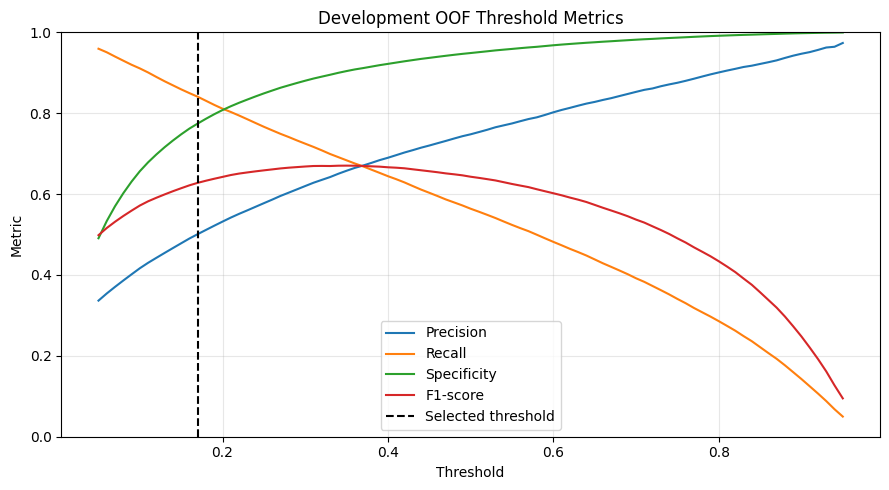

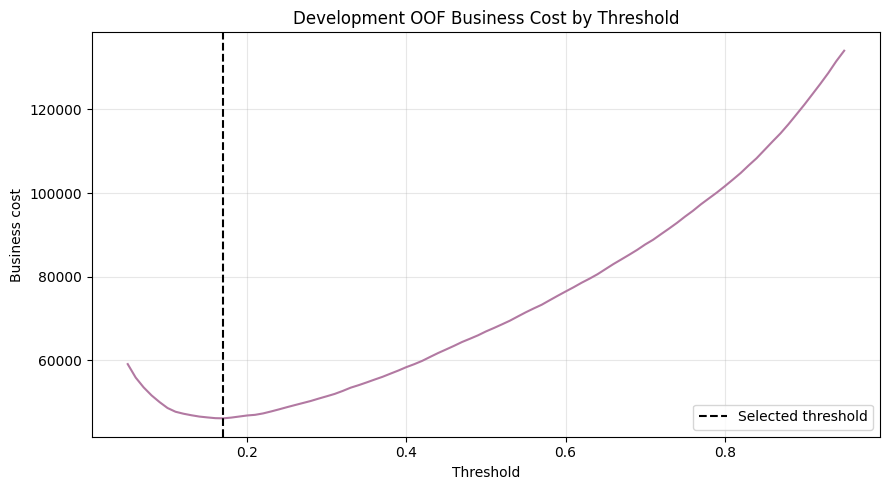

In [18]:
plt.figure(figsize=(9, 5))
plt.plot(threshold_results_df["Threshold"], threshold_results_df["Precision"], label="Precision")
plt.plot(threshold_results_df["Threshold"], threshold_results_df["Recall"], label="Recall")
plt.plot(threshold_results_df["Threshold"], threshold_results_df["Specificity"], label="Specificity")
plt.plot(threshold_results_df["Threshold"], threshold_results_df["F1-score"], label="F1-score")
plt.axvline(SELECTED_THRESHOLD, color="black", linestyle="--", label="Selected threshold")
plt.title("Development OOF Threshold Metrics")
plt.xlabel("Threshold")
plt.ylabel("Metric")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(threshold_results_df["Threshold"], threshold_results_df["Business Cost"], color="#B279A2")
plt.axvline(SELECTED_THRESHOLD, color="black", linestyle="--", label="Selected threshold")
plt.title("Development OOF Business Cost by Threshold")
plt.xlabel("Threshold")
plt.ylabel("Business cost")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 13. Final Holdout Evaluation

The model, hyperparameters, surname decision, and threshold are frozen before this section runs. The holdout set
is used here for final evaluation.


In [19]:
frozen_model_name = selected_model_name
frozen_threshold = SELECTED_THRESHOLD
final_model = clone(selected_model_template)
final_model.fit(X_development, y_development)

holdout_fe = add_bank_features(holdout_df)
X_holdout = holdout_fe.drop(columns=NON_FEATURE_COLUMNS, errors="raise")
y_holdout = holdout_fe[TARGET].astype(int)

for forbidden_column in NON_FEATURE_COLUMNS:
    assert forbidden_column not in X_holdout.columns, f"{forbidden_column} leaked into holdout features."

holdout_probabilities = final_model.predict_proba(X_holdout)[:, 1]
holdout_predictions = (holdout_probabilities >= frozen_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_holdout, holdout_predictions, labels=[0, 1]).ravel()
holdout_business_cost = fn * FALSE_NEGATIVE_COST + fp * FALSE_POSITIVE_COST

final_metrics = {
    "Model": frozen_model_name,
    "Threshold": frozen_threshold,
    "ROC-AUC": roc_auc_score(y_holdout, holdout_probabilities),
    "PR-AUC": average_precision_score(y_holdout, holdout_probabilities),
    "Accuracy": accuracy_score(y_holdout, holdout_predictions),
    "Precision": precision_score(y_holdout, holdout_predictions, zero_division=0),
    "Recall": recall_score(y_holdout, holdout_predictions, zero_division=0),
    "F1-score": f1_score(y_holdout, holdout_predictions, zero_division=0),
    "False Positive": int(fp),
    "False Negative": int(fn),
    "Business Cost": int(holdout_business_cost),
}

final_metrics_df = pd.DataFrame([final_metrics])
final_confusion_matrix = confusion_matrix(y_holdout, holdout_predictions, labels=[0, 1])

print(final_metrics_df)
print("\nFinal confusion matrix:")
print(final_confusion_matrix)
print("\nClassification report:")
print(classification_report(y_holdout, holdout_predictions, zero_division=0))


           Model  Threshold   ROC-AUC    PR-AUC  Accuracy  Precision    Recall  F1-score  False Positive  False Negative  Business Cost
0  XGBoost Tuned       0.17  0.893718  0.739135  0.790711   0.500044  0.838027   0.62635            5623            1087          11058

Final confusion matrix:
[[19727  5623]
 [ 1087  5624]]

Classification report:
              precision    recall  f1-score   support

           0       0.95      0.78      0.85     25350
           1       0.50      0.84      0.63      6711

    accuracy                           0.79     32061
   macro avg       0.72      0.81      0.74     32061
weighted avg       0.85      0.79      0.81     32061



c:\Users\admin\.conda\envs\dsp\lib\site-packages\xgboost\core.py:751: UserWarning: [22:42:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


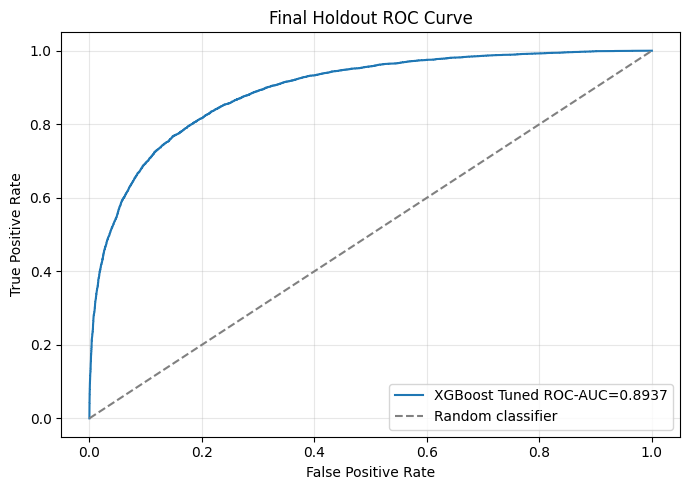

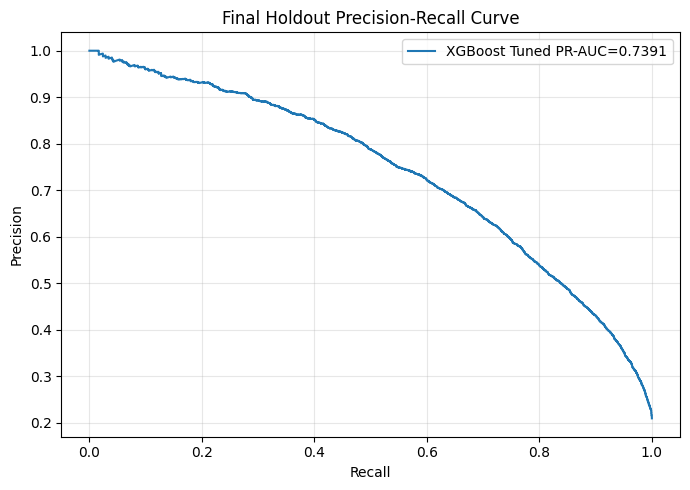

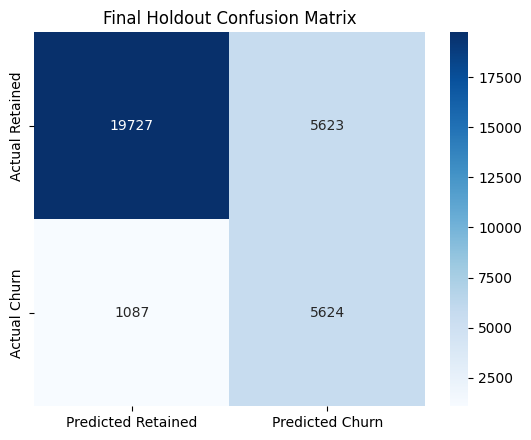

In [20]:
fpr, tpr, _ = roc_curve(y_holdout, holdout_probabilities)
precision_curve, recall_curve, _ = precision_recall_curve(y_holdout, holdout_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"{frozen_model_name} ROC-AUC={final_metrics['ROC-AUC']:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
plt.title("Final Holdout ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(recall_curve, precision_curve, label=f"{frozen_model_name} PR-AUC={final_metrics['PR-AUC']:.4f}")
plt.title("Final Holdout Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(5.5, 4.5))
if SEABORN_AVAILABLE:
    sns.heatmap(
        final_confusion_matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted Retained", "Predicted Churn"],
        yticklabels=["Actual Retained", "Actual Churn"],
    )
else:
    plt.imshow(final_confusion_matrix, cmap="Blues")
    for row_index in range(final_confusion_matrix.shape[0]):
        for column_index in range(final_confusion_matrix.shape[1]):
            plt.text(column_index, row_index, final_confusion_matrix[row_index, column_index], ha="center", va="center")
    plt.xticks([0, 1], ["Predicted Retained", "Predicted Churn"], rotation=20)
    plt.yticks([0, 1], ["Actual Retained", "Actual Churn"])
plt.title("Final Holdout Confusion Matrix")
plt.tight_layout()
plt.show()


In [40]:
import os

os.makedirs("figures", exist_ok=True)

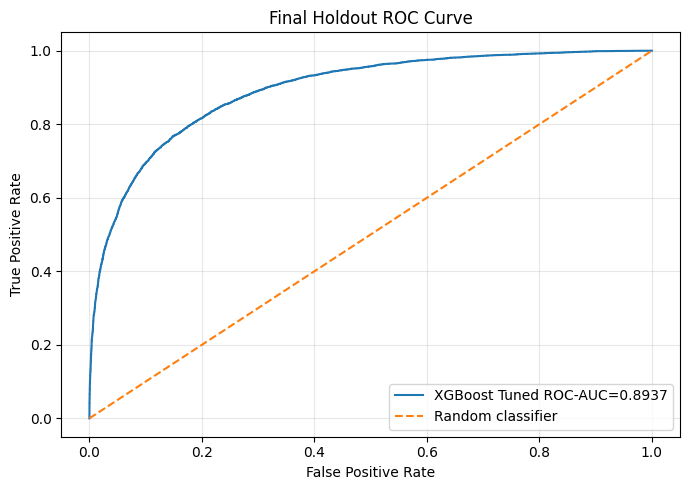

In [42]:
# ================================
# ROC Curve Export for IEEE Paper
# ================================

fpr, tpr, _ = roc_curve(
    y_holdout,
    holdout_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"{frozen_model_name} ROC-AUC={final_metrics['ROC-AUC']:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.title("Final Holdout ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

# Save figure for IEEE paper
plt.savefig(
    "figures/roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 14. Explainable Artificial Intelligence

This section implements XGBoost feature importance when XGBoost is available, permutation importance for the
frozen final model, and optional SHAP. If SHAP is unavailable, the notebook continues normally.


XGBoost feature importance reference:
XGBoost Tuned

Top 20 XGBoost feature importances:
                            Feature  Importance
0              cat__NumOfProducts_2    0.376468
1              cat__NumOfProducts_1    0.124422
2   num__ProductActivityInteraction    0.056090
3              cat__IsZeroBalance_1    0.044961
4        num__AgeProductInteraction    0.038682
5        cat__InactiveWithBalance_0    0.032663
6              cat__IsZeroBalance_0    0.025244
7                          num__Age    0.023219
8            cat__Geography_Germany    0.022937
9                cat__Gender_Female    0.018943
10          cat__IsActiveMember_0.0    0.013674
11                 cat__Gender_Male    0.011280
12          cat__ActiveCardHolder_1    0.008984
13             cat__NumOfProducts_3    0.008109
14           num__BalancePerProduct    0.007139
15          cat__ActiveCardHolder_0    0.006407
16            cat__Surname_McGregor    0.005059
17  cat__Surname_infrequent_sklearn    0.004771

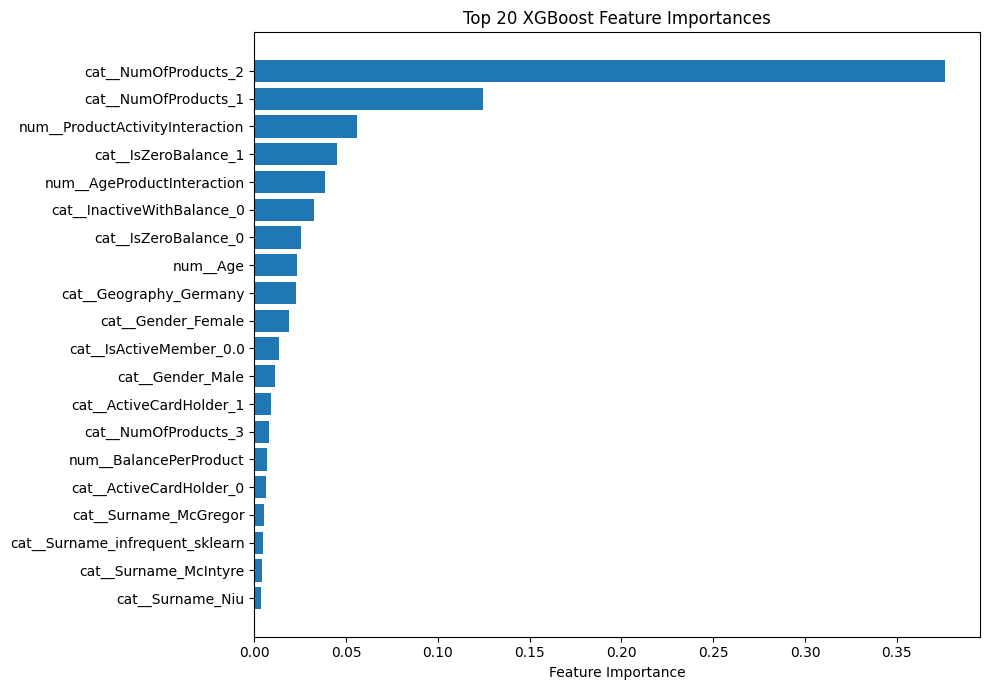

In [44]:
feature_importance_reference_model = None
feature_importance_reference_name = None

if XGBOOST_AVAILABLE:
    if frozen_model_name.startswith("XGBoost"):
        feature_importance_reference_model = final_model
        feature_importance_reference_name = frozen_model_name
    else:
        feature_importance_reference_model = build_model_pipeline("xgboost", include_surname=USE_SURNAME)
        feature_importance_reference_model.fit(X_development, y_development)
        feature_importance_reference_name = "XGBoost explanation model fitted on development data"

if feature_importance_reference_model is not None:
    xgb_preprocessor = feature_importance_reference_model.named_steps["preprocessor"]
    xgb_classifier = feature_importance_reference_model.named_steps["classifier"]
    transformed_feature_names = xgb_preprocessor.get_feature_names_out()

    xgb_feature_importance_df = pd.DataFrame({
        "Feature": transformed_feature_names,
        "Importance": xgb_classifier.feature_importances_,
    }).sort_values("Importance", ascending=False).reset_index(drop=True)

    print("XGBoost feature importance reference:")
    print(feature_importance_reference_name)

    print("\nTop 20 XGBoost feature importances:")
    print(xgb_feature_importance_df.head(20))

    plt.figure(figsize=(10, 7))

    top_xgb_importances = (
        xgb_feature_importance_df
        .head(20)
        .sort_values("Importance", ascending=True)
    )

    plt.barh(
        top_xgb_importances["Feature"],
        top_xgb_importances["Importance"]
    )

    plt.title("Top 20 XGBoost Feature Importances")
    plt.xlabel("Feature Importance")

    plt.tight_layout()

    # ================================
    # Export figure for IEEE paper
    # ================================
    import os

    os.makedirs("figures", exist_ok=True)

    plt.savefig(
        "figures/xgboost_feature_importance.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    xgb_feature_importance_df = pd.DataFrame(
        columns=["Feature", "Importance"]
    )

    print(
        "XGBoost feature importance is unavailable because XGBoost is not installed."
    )


In [43]:
import os

# Create figures folder if it does not exist
os.makedirs("figures", exist_ok=True)

# Save figure for IEEE paper
plt.savefig(
    "figures/xgboost_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

Top 20 permutation importances on development sample:
                       Feature  Importance Mean  Importance Std
0                NumOfProducts         0.186247        0.002914
1        AgeProductInteraction         0.030754        0.001673
2                          Age         0.018859        0.002033
3   ProductActivityInteraction         0.018109        0.000806
4                    Geography         0.017277        0.000511
5            BalancePerProduct         0.015424        0.001148
6                      Surname         0.012033        0.000958
7                       Gender         0.007962        0.000992
8                      Balance         0.003177        0.000563
9                  CreditScore         0.003111        0.000348
10         CreditScoreAgeRatio         0.002898        0.000546
11         InactiveWithBalance         0.001894        0.000264
12              TenureAgeRatio         0.001642        0.000305
13            ActiveCardHolder         0.001436   

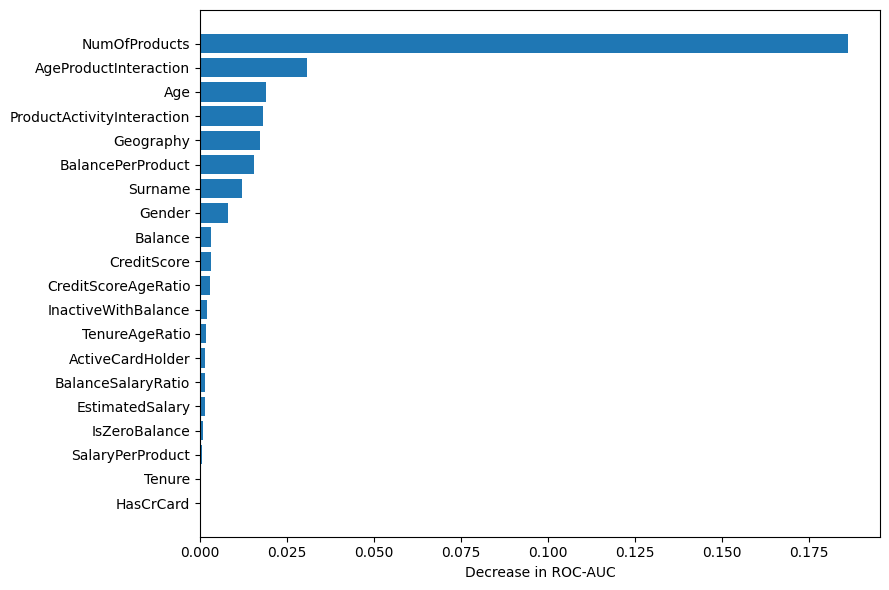

In [45]:
import os

# Create figures folder
os.makedirs("figures", exist_ok=True)


permutation_sample_size = min(5000, len(X_development))

permutation_sample = X_development.sample(
    n=permutation_sample_size,
    random_state=RANDOM_STATE
)

permutation_target = y_development.loc[
    permutation_sample.index
]


permutation_result = permutation_importance(
    final_model,
    permutation_sample,
    permutation_target,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)


permutation_importance_df = pd.DataFrame({
    "Feature": X_development.columns,
    "Importance Mean": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std,
}).sort_values(
    "Importance Mean",
    ascending=False
).reset_index(drop=True)


print("Top 20 permutation importances on development sample:")
print(permutation_importance_df.head(20))


# ================================
# Plot for IEEE paper
# ================================

plt.figure(figsize=(9, 6))


top_permutation = (
    permutation_importance_df
    .head(20)
    .sort_values(
        "Importance Mean",
        ascending=True
    )
)


plt.barh(
    top_permutation["Feature"],
    top_permutation["Importance Mean"]
)


plt.xlabel("Decrease in ROC-AUC")

plt.tight_layout()


# Save figure
plt.savefig(
    "figures/permutation_importance.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

### 14.1 Pipeline-Aware SHAP Explanation

The final model is a sklearn pipeline that includes preprocessing and categorical encoding before the XGBoost classifier. SHAP explanations must use the transformed numerical feature matrix produced by the fitted preprocessor, not the raw dataframe containing categorical strings. The transformed feature names are recovered from the fitted `ColumnTransformer` with `get_feature_names_out()`.

For XGBoost 2.x, some SHAP versions can fail while parsing the model base score through `TreeExplainer`. To avoid that compatibility issue, this notebook uses XGBoost's native contribution calculation (`pred_contribs=True`) on the transformed matrix, then wraps the resulting contribution values in a SHAP `Explanation` for plotting.


In [ ]:
required_shap_variables = ["final_model", "X_holdout", "holdout_probabilities", "frozen_model_name"]
missing_shap_variables = [name for name in required_shap_variables if name not in globals()]

if missing_shap_variables:
    print("SHAP explanation is pending final model evaluation.")
    print(f"Missing variables: {missing_shap_variables}")
elif not SHAP_AVAILABLE:
    print("SHAP is not installed. Skipping SHAP explanation. Other Explainable AI methods remain available.")
elif not XGBOOST_AVAILABLE:
    print("XGBoost is unavailable. Skipping SHAP contribution plots. Other Explainable AI methods remain available.")
elif not frozen_model_name.startswith("XGBoost"):
    print(
        "The frozen final model is not XGBoost, so SHAP contribution plots for the final model are skipped. "
        "XGBoost feature importance and permutation importance remain available."
    )
else:
    try:
        preprocessor = final_model.named_steps["preprocessor"]
        classifier = final_model.named_steps["classifier"]

        X_holdout_transformed = preprocessor.transform(X_holdout)
        feature_names = np.array(preprocessor.get_feature_names_out()).astype(str)

        SHAP_SAMPLE_SIZE = min(2000, X_holdout_transformed.shape[0])
        shap_sample = X_holdout_transformed[:SHAP_SAMPLE_SIZE]
        shap_sample_probabilities = np.asarray(holdout_probabilities[:SHAP_SAMPLE_SIZE])

        if hasattr(shap_sample, "toarray"):
            shap_sample = shap_sample.toarray()

        shap_sample = np.asarray(shap_sample, dtype=np.float32)

        booster = classifier.get_booster()
        shap_dmatrix = xgb.DMatrix(shap_sample)
        shap_contributions = booster.predict(
            shap_dmatrix,
            pred_contribs=True,
            validate_features=False,
        )

        shap_values_array = shap_contributions[:, :-1]
        shap_base_values = shap_contributions[:, -1]
        shap_values = shap.Explanation(
            values=shap_values_array,
            base_values=shap_base_values,
            data=shap_sample,
            feature_names=list(feature_names),
        )

        print("SHAP explanation uses transformed numerical holdout features.")
        print("SHAP values were computed with XGBoost native pred_contribs for XGBoost 2.x compatibility.")
        print(f"Transformed SHAP sample shape: {shap_sample.shape}")
        print(f"Number of transformed feature names: {len(feature_names)}")

        shap.summary_plot(
            shap_values_array,
            shap_sample,
            feature_names=feature_names,
            plot_type="bar",
            show=True,
        )

        import os
        import matplotlib.pyplot as plt

        # Create figures folder
        os.makedirs("figures", exist_ok=True)

        # Save SHAP summary plot
        plt.figure(figsize=(10, 7))

        shap.summary_plot(
            shap_values_array,
            shap_sample,
            feature_names=feature_names,
            show=False
        )

        plt.tight_layout()

        plt.savefig(
            "figures/shap_summary.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        high_risk_position = int(np.argmax(shap_sample_probabilities))
        low_risk_position = int(np.argmin(shap_sample_probabilities))

        print("High-risk SHAP sample position:")
        print(high_risk_position)
        print("High-risk churn probability:")
        print(float(shap_sample_probabilities[high_risk_position]))

        print("Low-risk SHAP sample position:")
        print(low_risk_position)
        print("Low-risk churn probability:")
        print(float(shap_sample_probabilities[low_risk_position]))

        if hasattr(shap, "plots") and hasattr(shap.plots, "waterfall"):

            import os
            import matplotlib.pyplot as plt

            os.makedirs("figures", exist_ok=True)

            # High-risk customer waterfall plot
            shap.plots.waterfall(
                shap_values[high_risk_position],
                max_display=20,
                show=False
            )

            plt.tight_layout()

            plt.savefig(
                "figures/shap_waterfall.png",
                dpi=300,
                bbox_inches="tight"
            )

            plt.show()


        else:
            print(
                "SHAP waterfall plots are not supported by the installed SHAP version."
            )

SyntaxError: incomplete input (3852414855.py, line 130)

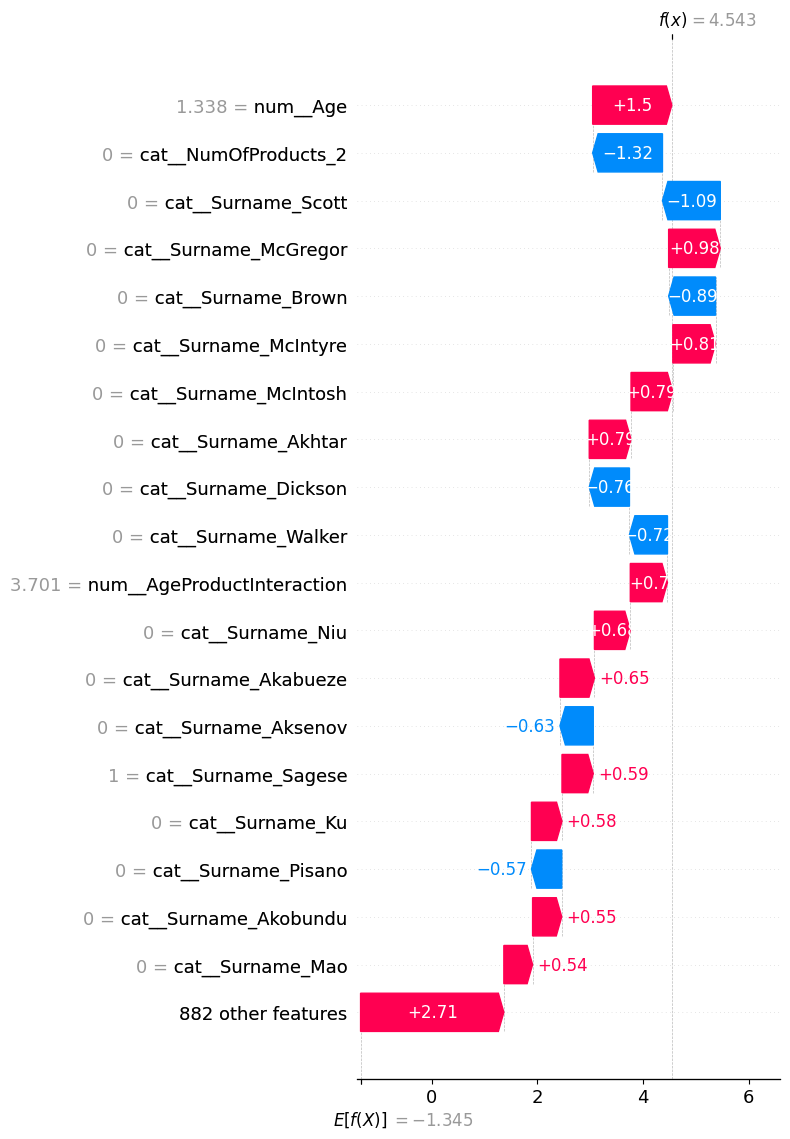

Saved: figures/shap_waterfall.png


In [53]:
import os
import matplotlib.pyplot as plt


# Check SHAP variables
if "shap_values" in globals() and "high_risk_position" in globals():

    os.makedirs("figures", exist_ok=True)

    shap.plots.waterfall(
        shap_values[high_risk_position],
        max_display=20,
        show=False
    )

    plt.tight_layout()

    plt.savefig(
        "figures/shap_waterfall.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved: figures/shap_waterfall.png")

else:
    print("Missing SHAP variables. Run SHAP explanation cell first.")

       Risk Group  Customers  Actual_Churn_Rate
0        Low Risk      23248           6.869408
1     Medium Risk       3751          35.883764
2       High Risk       2470          60.445344
3  Very High Risk       2592          87.770062


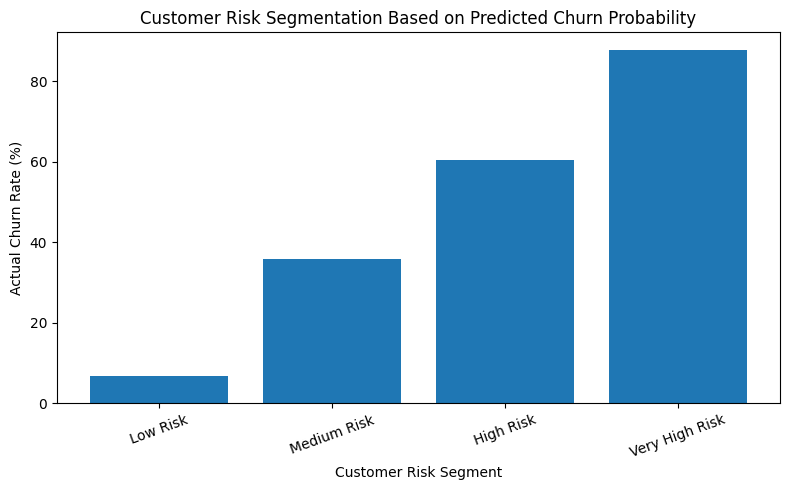

In [54]:
import os
import matplotlib.pyplot as plt
import pandas as pd


os.makedirs("figures", exist_ok=True)


# Create risk segmentation dataframe

risk_df = pd.DataFrame({
    "Churn Probability": holdout_probabilities,
    "Actual": y_holdout.values
})


# Define risk groups based on churn probability

risk_df["Risk Group"] = pd.cut(
    risk_df["Churn Probability"],
    bins=[0, 0.25, 0.50, 0.75, 1.0],
    labels=[
        "Low Risk",
        "Medium Risk",
        "High Risk",
        "Very High Risk"
    ],
    include_lowest=True
)


# Calculate statistics

risk_summary = (
    risk_df
    .groupby("Risk Group", observed=False)
    .agg(
        Customers=("Actual", "count"),
        Actual_Churn_Rate=("Actual", "mean")
    )
    .reset_index()
)


risk_summary["Actual_Churn_Rate"] *= 100


print(risk_summary)


# ==========================
# Plot risk segmentation
# ==========================

plt.figure(figsize=(8, 5))


plt.bar(
    risk_summary["Risk Group"],
    risk_summary["Actual_Churn_Rate"]
)


plt.xlabel("Customer Risk Segment")
plt.ylabel("Actual Churn Rate (%)")

plt.title(
    "Customer Risk Segmentation Based on Predicted Churn Probability"
)


plt.xticks(rotation=20)

plt.tight_layout()


plt.savefig(
    "figures/risk_segmentation.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

## 15. Customer Risk Segmentation

Risk groups are created from development out-of-fold probabilities using the selected threshold. This avoids
using holdout outcomes for segmentation design.


In [35]:
risk_df = development_fe[[
    "CustomerId",
    "Geography",
    "Gender",
    "Age",
    "NumOfProducts",
    "IsActiveMember",
    "Balance",
    TARGET,
]].copy()

risk_df["ChurnProbability"] = selected_model_oof_probabilities
risk_df["PredictedChurn"] = risk_df["ChurnProbability"].ge(SELECTED_THRESHOLD).astype(int)
risk_df["AgeGroup"] = pd.cut(
    risk_df["Age"],
    bins=[0, 30, 40, 50, 60, np.inf],
    labels=["18-30", "31-40", "41-50", "51-60", "60+"],
    include_lowest=True,
)
risk_df["ActivityStatus"] = np.where(risk_df["IsActiveMember"].eq(1), "Active", "Inactive")

risk_conditions = [
    risk_df["ChurnProbability"].ge(0.75),
    risk_df["ChurnProbability"].ge(SELECTED_THRESHOLD) & risk_df["ChurnProbability"].lt(0.75),
    risk_df["ChurnProbability"].ge(0.5 * SELECTED_THRESHOLD) & risk_df["ChurnProbability"].lt(SELECTED_THRESHOLD),
    risk_df["ChurnProbability"].lt(0.5 * SELECTED_THRESHOLD),
]
risk_labels = ["Very High Risk", "High Risk", "Medium Risk", "Low Risk"]
risk_df["RiskGroup"] = np.select(risk_conditions, risk_labels, default="Medium Risk")

predicted_churn_risk_groups = set(risk_df.loc[risk_df["PredictedChurn"].eq(1), "RiskGroup"].unique())
assert predicted_churn_risk_groups.issubset({"High Risk", "Very High Risk"}), "Predicted churn customers fell outside high-risk groups."

risk_group_summary = (
    risk_df.groupby("RiskGroup", observed=False)
    .agg(
        CustomerCount=("CustomerId", "size"),
        AverageChurnProbability=("ChurnProbability", "mean"),
        ActualChurnRate=(TARGET, "mean"),
        PredictedChurnCount=("PredictedChurn", "sum"),
        AverageBalance=("Balance", "mean"),
    )
    .reset_index()
    .sort_values("AverageChurnProbability", ascending=False)
)

print(risk_group_summary)
print("\nPredicted churn risk groups:")
print(predicted_churn_risk_groups)


        RiskGroup  CustomerCount  AverageChurnProbability  ActualChurnRate  PredictedChurnCount  AverageBalance
3  Very High Risk          10983                 0.871845         0.875262                10983    68300.157899
0       High Risk          36360                 0.391784         0.387899                36360    74819.716737
2     Medium Risk          18853                 0.122307         0.126028                    0    87212.426390
1        Low Risk          66777                 0.031548         0.031703                    0    34063.465305

Predicted churn risk groups:
{'High Risk', 'Very High Risk'}


In [36]:
def risk_summary_by(column):
    return (
        risk_df.groupby([column, "RiskGroup"], observed=False)
        .agg(
            CustomerCount=("CustomerId", "size"),
            AverageChurnProbability=("ChurnProbability", "mean"),
            ActualChurnRate=(TARGET, "mean"),
        )
        .reset_index()
        .sort_values([column, "AverageChurnProbability"], ascending=[True, False])
    )

risk_analysis_tables = {
    "Geography": risk_summary_by("Geography"),
    "Gender": risk_summary_by("Gender"),
    "AgeGroup": risk_summary_by("AgeGroup"),
    "ActivityStatus": risk_summary_by("ActivityStatus"),
    "NumOfProducts": risk_summary_by("NumOfProducts"),
}

for name, table in risk_analysis_tables.items():
    print(f"\nRisk analysis by {name}:")
    print(table)



Risk analysis by Geography:
   Geography       RiskGroup  CustomerCount  AverageChurnProbability  ActualChurnRate
3     France  Very High Risk           4237                 0.868145         0.876092
0     France       High Risk          16651                 0.380624         0.376794
2     France     Medium Risk          10381                 0.121680         0.125325
1     France        Low Risk          44701                 0.029829         0.029373
7    Germany  Very High Risk           5108                 0.876288         0.876468
4    Germany       High Risk          12868                 0.412774         0.410942
6    Germany     Medium Risk           4412                 0.124215         0.129873
5    Germany        Low Risk           5558                 0.048905         0.051098
11     Spain  Very High Risk           1638                 0.867559         0.869353
8      Spain       High Risk           6841                 0.379466         0.371583
10     Spain     Medium R

## 16. Banking Retention Strategy

Retention recommendations are banking-specific and based on churn risk plus customer attributes.


In [37]:
def recommend_banking_retention_strategy(row):
    recommendations = []
    if row["RiskGroup"] in {"High Risk", "Very High Risk"}:
        recommendations.append("Prioritize for proactive retention outreach")
    if row["IsActiveMember"] == 0 and row["Balance"] > 0:
        recommendations.append("Run a proactive retention campaign for inactive customers with balance")
    if row["NumOfProducts"] == 1:
        recommendations.append("Offer a needs-based cross-selling strategy for a suitable second product")
    if row["Balance"] >= risk_df["Balance"].quantile(0.75) and row["RiskGroup"] in {"High Risk", "Very High Risk"}:
        recommendations.append("Offer a premium retention program for high-value churn risk")
    if row["IsActiveMember"] == 0:
        recommendations.append("Use an engagement campaign with service reminders or relationship manager contact")
    if not recommendations:
        recommendations.append("Maintain standard loyalty communication and monitor risk changes")
    return "; ".join(recommendations)


retention_df = risk_df.copy()
retention_df["RetentionStrategy"] = retention_df.apply(recommend_banking_retention_strategy, axis=1)
retention_priority_df = retention_df.sort_values(
    by=["RiskGroup", "ChurnProbability", "Balance"],
    ascending=[False, False, False],
).reset_index(drop=True)

retention_strategy_summary = (
    retention_df.groupby("RetentionStrategy", observed=False)
    .agg(
        CustomerCount=("CustomerId", "size"),
        AverageChurnProbability=("ChurnProbability", "mean"),
        AverageBalance=("Balance", "mean"),
    )
    .reset_index()
    .sort_values("CustomerCount", ascending=False)
)

print("Retention strategy summary:")
print(retention_strategy_summary.head(20))
print("\nTop priority customers from development OOF risk analysis:")
print(retention_priority_df.head(20))


Retention strategy summary:
                                    RetentionStrategy  CustomerCount  AverageChurnProbability  AverageBalance
0   Maintain standard loyalty communication and mo...          35077                 0.029299    27836.082642
15  Use an engagement campaign with service remind...          22047                 0.035519        0.000000
1   Offer a needs-based cross-selling strategy for...          16476                 0.081583    95077.957122
6   Prioritize for proactive retention outreach; O...          10795                 0.574310        0.000000
8   Prioritize for proactive retention outreach; R...           8644                 0.533335   138995.483714
4   Prioritize for proactive retention outreach; O...           8625                 0.405979    41115.436567
9   Prioritize for proactive retention outreach; R...           6932                 0.535337   101208.707314
13  Run a proactive retention campaign for inactiv...           6481                 0.10864

## 17. Dynamic Final Conclusion

The conclusion is generated from notebook variables, so model metrics and important features are not hard-coded.


In [27]:
def format_metric(value, digits=4):
    if value is None or pd.isna(value):
        return "N/A"
    return f"{float(value):.{digits}f}"


def get_top_features():
    if "permutation_importance_df" in globals() and not permutation_importance_df.empty:
        return permutation_importance_df.head(5)["Feature"].tolist()
    if "xgb_feature_importance_df" in globals() and not xgb_feature_importance_df.empty:
        return xgb_feature_importance_df.head(5)["Feature"].tolist()
    return []


required_conclusion_variables = [
    "final_metrics_df",
    "selected_model_name",
    "SELECTED_THRESHOLD",
    "risk_group_summary",
    "retention_strategy_summary",
]
missing_conclusion_variables = [name for name in required_conclusion_variables if name not in globals()]

if missing_conclusion_variables:
    print("Final conclusion is pending notebook execution.")
    print(f"Missing variables: {missing_conclusion_variables}")
else:
    final_row = final_metrics_df.iloc[0]
    top_features = get_top_features()
    high_risk_count = int(risk_df["RiskGroup"].isin(["High Risk", "Very High Risk"]).sum())
    conclusion_lines = [
        "Final Dynamic Conclusion",
        "",
        f"Dataset: {len(df)} customer records with {df.shape[1] - 1} non-target columns before feature engineering.",
        f"Validation method: grouped 80/20 holdout using CustomerId, with {MODEL_CV_SPLITS}-fold grouped development cross-validation.",
        f"Best model selected from development ROC-AUC: {selected_model_name}.",
        f"Final holdout ROC-AUC: {format_metric(final_row['ROC-AUC'])}.",
        f"Final holdout PR-AUC: {format_metric(final_row['PR-AUC'])}.",
        f"Final holdout F1-score: {format_metric(final_row['F1-score'])}.",
        f"Selected threshold from development OOF probabilities: {format_metric(SELECTED_THRESHOLD, digits=2)}.",
        f"Important features from explainability: {', '.join(top_features) if top_features else 'pending explainability results'}.",
        f"High and very high risk customers identified in development OOF analysis: {high_risk_count}.",
        "Retention recommendations focus on proactive outreach, cross-selling for single-product customers, premium retention for high-value churn risk, and engagement campaigns for inactive customers.",
        "Limitations: the workflow is based on historical tabular records, business costs are assumed for threshold optimization, and customer-level grouping reduces leakage but does not prove future causal retention impact.",
    ]
    print("\n".join(conclusion_lines))


Final Dynamic Conclusion

Dataset: 165034 customer records with 13 non-target columns before feature engineering.
Validation method: grouped 80/20 holdout using CustomerId, with 5-fold grouped development cross-validation.
Best model selected from development ROC-AUC: XGBoost Tuned.
Final holdout ROC-AUC: 0.8937.
Final holdout PR-AUC: 0.7391.
Final holdout F1-score: 0.6264.
Selected threshold from development OOF probabilities: 0.17.
Important features from explainability: NumOfProducts, AgeProductInteraction, Age, ProductActivityInteraction, Geography.
High and very high risk customers identified in development OOF analysis: 47343.
Retention recommendations focus on proactive outreach, cross-selling for single-product customers, premium retention for high-value churn risk, and engagement campaigns for inactive customers.
Limitations: the workflow is based on historical tabular records, business costs are assumed for threshold optimization, and customer-level grouping reduces leakage b

In [55]:
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score


def run_ablation_experiment(
    include_feature_engineering=False,
    include_surname=False
):

    X_train = X_development.copy()
    X_test = X_holdout.copy()

    y_train = y_development.copy()
    y_test = y_holdout.copy()


    # Remove Surname
    if not include_surname:
        X_train = X_train.drop(columns=["Surname"])
        X_test = X_test.drop(columns=["Surname"])


    # Feature engineering
    if include_feature_engineering:

        def add_features(df):

            df = df.copy()

            df["BalancePerProduct"] = (
                df["Balance"] /
                (df["NumOfProducts"] + 1)
            )

            df["BalanceSalaryRatio"] = (
                df["Balance"] /
                (df["EstimatedSalary"] + 1)
            )

            df["SalaryPerProduct"] = (
                df["EstimatedSalary"] /
                (df["NumOfProducts"] + 1)
            )

            df["ProductActivityInteraction"] = (
                df["NumOfProducts"] *
                df["IsActiveMember"]
            )

            df["AgeProductInteraction"] = (
                df["Age"] *
                df["NumOfProducts"]
            )

            df["CreditScoreAgeRatio"] = (
                df["CreditScore"] /
                (df["Age"] + 1)
            )

            return df


        X_train = add_features(X_train)
        X_test = add_features(X_test)



    model = build_model_pipeline(
        "xgboost",
        include_surname=include_surname
    )


    model.fit(
        X_train,
        y_train
    )


    probabilities = model.predict_proba(
        X_test
    )[:,1]


    auc = roc_auc_score(
        y_test,
        probabilities
    )

    pr_auc = average_precision_score(
        y_test,
        probabilities
    )


    predictions = (
        probabilities >= 0.5
    ).astype(int)


    f1 = f1_score(
        y_test,
        predictions
    )


    return {
        "ROC-AUC": auc,
        "PR-AUC": pr_auc,
        "F1-score": f1
    }

In [56]:
ablation_results = []


configs = [

    (
        "Baseline",
        False,
        False
    ),

    (
        "+ Surname",
        False,
        True
    ),

    (
        "+ Feature Engineering",
        True,
        False
    ),

    (
        "Proposed Framework",
        True,
        True
    )

]


for name, fe, surname in configs:

    print(
        f"Running {name}"
    )

    result = run_ablation_experiment(
        include_feature_engineering=fe,
        include_surname=surname
    )

    result["Configuration"] = name

    ablation_results.append(result)



ablation_df = pd.DataFrame(
    ablation_results
)


ablation_df = ablation_df[
    [
        "Configuration",
        "ROC-AUC",
        "PR-AUC",
        "F1-score"
    ]
]


ablation_df

Running Baseline
Running + Surname
Running + Feature Engineering
Running Proposed Framework


,Configuration,ROC-AUC,PR-AUC,F1-score
0,Baseline,0.883813,0.715180,0.641505
1,+ Surname,0.891699,0.734588,0.649290
2,+ Feature Engineering,0.884500,0.715991,0.643597
3,Proposed Framework,0.891458,0.733666,0.646205


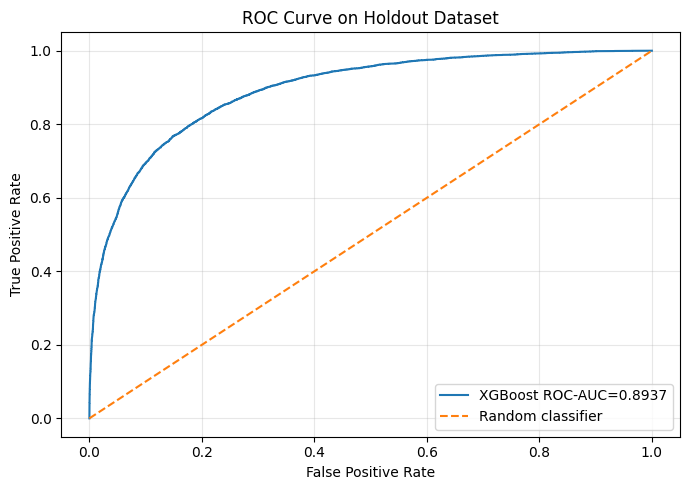

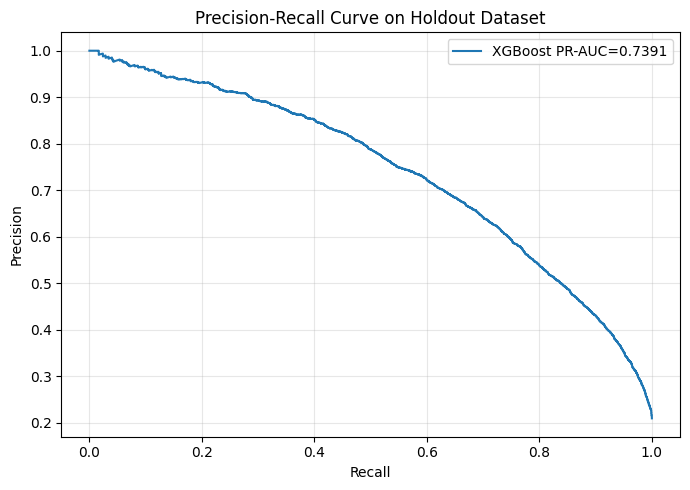

In [57]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

os.makedirs("figures", exist_ok=True)

# ROC Curve
fpr, tpr, _ = roc_curve(
    y_holdout,
    holdout_probabilities
)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost ROC-AUC={final_metrics['ROC-AUC']:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on Holdout Dataset")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



# PR Curve
precision_curve, recall_curve, _ = precision_recall_curve(
    y_holdout,
    holdout_probabilities
)

plt.figure(figsize=(7,5))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"XGBoost PR-AUC={final_metrics['PR-AUC']:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve on Holdout Dataset")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/pr_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()